# Magnetic Circuit Reluctance Model

A quick sandbox for building simple series magnetic circuits (permanent magnet
+ core + air gap, etc.) using magnetic-circuit analogy:

- MMF (like voltage) — here driven by a permanent magnet's remanence
- Flux, $\Phi$ (like current)
- Reluctance, $\mathcal{R}$ (like resistance)

Analogy: $\text{MMF} = \Phi \cdot \mathcal{R}_{total}$, same as $V = I R$.

Each `ReluctanceElement` models one segment of the magnetic path (a piece of
core, an air gap, a magnet body, etc.). All attributes are public plain
Python floats/numpy arrays so you can vectorize over them directly.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

mu_0 = 4 * np.pi * 1e-7  # H/m, permeability of free space


## `ReluctanceElement` class

Represents one segment of the magnetic circuit:

$$\mathcal{R} = \frac{l}{\mu_0 \mu_r A}$$

- `length` — path length through the element, $l$ [m]
- `mu_r` — relative permeability, $\mu_r$ (dimensionless; use `mu_r=1` for an air gap)
- `area` — cross-sectional area, $A$ [m$^2$]

`length`, `mu_r`, and `area` can each be a scalar **or** a numpy array — since
everything is public and computed with plain numpy ops, broadcasting an array
into any attribute (e.g. sweeping air-gap length) just works, and
`reluctance` will come out as an array too.


In [4]:
class ReluctanceElement:
    """
    A single segment of a magnetic circuit, modeled as a reluctance.

    R = length / (mu_0 * mu_r * area)

    Parameters
    ----------
    length : float or np.ndarray
        Path length through the element [m].
    mu_r : float or np.ndarray
        Relative permeability of the material (dimensionless).
        Use mu_r = 1.0 for an air gap.
    area : float or np.ndarray
        Cross-sectional area normal to flux flow [m^2].

    All parameters are stored as public attributes so they can be
    read, overwritten, or swapped for numpy arrays for sweeps/plots.
    """

    def __init__(self, length, mu_r, area):
        self.length = length
        self.mu_r = mu_r
        self.area = area

    @property
    def reluctance(self):
        """Reluctance of this element [A-turns/Wb] (or A/Wb for a PM-only circuit)."""
        return self.length / (mu_0 * self.mu_r * self.area)

    def H_field(self, flux):
        """Magnetic field intensity H = Phi / (mu_0 * mu_r * A) inside this element."""
        return flux / (mu_0 * self.mu_r * self.area)

    def B_field(self, flux):
        """Flux density B = Phi / A inside this element."""
        return flux / self.area

    def voltage_drop(self, flux):
        """MMF drop across this element for a given flux: Phi * R."""
        return flux * self.reluctance

    def __repr__(self):
        return (f"ReluctanceElement(length={self.length}, mu_r={self.mu_r}, "
                f"area={self.area}, reluctance={self.reluctance})")


## Permanent magnet as the MMF source

A permanent magnet is modeled with a linear second-quadrant demagnetization
curve:

$$B = \mu_0 \mu_r H + B_r$$

where $B_r$ is the **remanence**. Its equivalent MMF source is:

$$\text{MMF}_{PM} = H_c \cdot l_m = \frac{B_r}{\mu_0 \mu_{r,m}} \cdot l_m$$

and the magnet itself also has its own reluctance (`ReluctanceElement` with
its own `length`, `mu_r`, `area`), which goes in series with the rest of the
circuit.

For a **series circuit** of the magnet + core + air gap (all carrying the
same flux $\Phi$), Ampere's law around the loop gives:

$$\text{MMF}_{PM} = \Phi \cdot (\mathcal{R}_{magnet} + \mathcal{R}_{core} + \mathcal{R}_{gap} + \dots)$$

$$\Phi = \frac{\text{MMF}_{PM}}{\mathcal{R}_{total}}$$

Below is a small helper function that ties a PM source to a list of
`ReluctanceElement`s in series and returns flux, plus a function to pull
H-field / B-field out of any element for that flux.


In [5]:
def pm_mmf(B_r, mu_r_magnet, length_magnet):
    """
    Equivalent MMF source of a permanent magnet (linear demag model).

    MMF = (B_r / (mu_0 * mu_r_magnet)) * length_magnet

    Parameters
    ----------
    B_r : float or np.ndarray
        Remanence of the magnet [T].
    mu_r_magnet : float or np.ndarray
        Relative recoil permeability of the magnet material.
    length_magnet : float or np.ndarray
        Magnet length along the magnetization direction [m].
    """
    H_c = B_r / (mu_0 * mu_r_magnet)
    return H_c * length_magnet


def solve_series_circuit(mmf_source, elements):
    """
    Solve a simple series magnetic circuit for flux.

    Parameters
    ----------
    mmf_source : float or np.ndarray
        Total driving MMF [A-turns].
    elements : list of ReluctanceElement
        Elements in series (e.g. [magnet, core, air_gap]).

    Returns
    -------
    flux : float or np.ndarray
        Flux through the series circuit [Wb].
    """
    R_total = sum(el.reluctance for el in elements)
    return mmf_source / R_total


## Example: PM + core + air gap (series circuit)

Set up a simple loop: permanent magnet → soft magnetic core → air gap → back
to the magnet. Adjust any parameter below and re-run.


In [10]:
# --- Permanent magnet ---
B_r = 1.28          # remanence [T] (e.g. NdFeB ~1.2 T)
mu_r_magnet = 1.05  # relative recoil permeability, typically close to 1
l_magnet = 7e-3*2     # magnet length [m]
A_magnet = np.pi*(0.01)**2  # magnet cross-sectional area [m^2]

magnet = ReluctanceElement(length=l_magnet, mu_r=mu_r_magnet, area=A_magnet)
MMF = pm_mmf(B_r, mu_r_magnet, l_magnet)

# --- Soft magnetic core (e.g. steel) ---
core = ReluctanceElement(length=(136.8+50+10)*1e-3, mu_r=4000, area=0.01*0.012)

# --- Air gap ---
air_gap = ReluctanceElement(length=3e-2, mu_r=1.0, area=np.pi*(5e-3)**2)

elements = [magnet, core, air_gap]

flux = solve_series_circuit(MMF, elements)

H_gap = air_gap.H_field(flux)
B_gap = air_gap.B_field(flux)

print(f"MMF source          : {MMF:.2f} A-turns")
print(f"Core reluctance      : {core.reluctance} A-turns/Wb" )
print(f"Total reluctance     : {sum(e.reluctance for e in elements):.2e} A-turns/Wb")
print(f"Flux                 : {flux:.2e} Wb")
print(f"Air-gap H field      : {H_gap:.2e} A/m")
print(f"Air-gap B field      : {B_gap:.4f} T")


MMF source          : 13581.22 A-turns
Core reluctance      : 326267.63333838544 A-turns/Wb
Total reluctance     : 3.38e+08 A-turns/Wb
Flux                 : 4.02e-05 Wb
Air-gap H field      : 4.07e+05 A/m
Air-gap B field      : 0.5115 T


## Sweep example: air-gap length vs. gap flux density

Because `length` on `ReluctanceElement` can be a numpy array, sweeping a
parameter is just a matter of assigning an array to that attribute and
recomputing — no changes to the class needed.


<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
C:\Users\RafIc\AppData\Local\Temp\ipykernel_22036\822820289.py:24: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_ylabel("Flux [$\mu$Wb]")


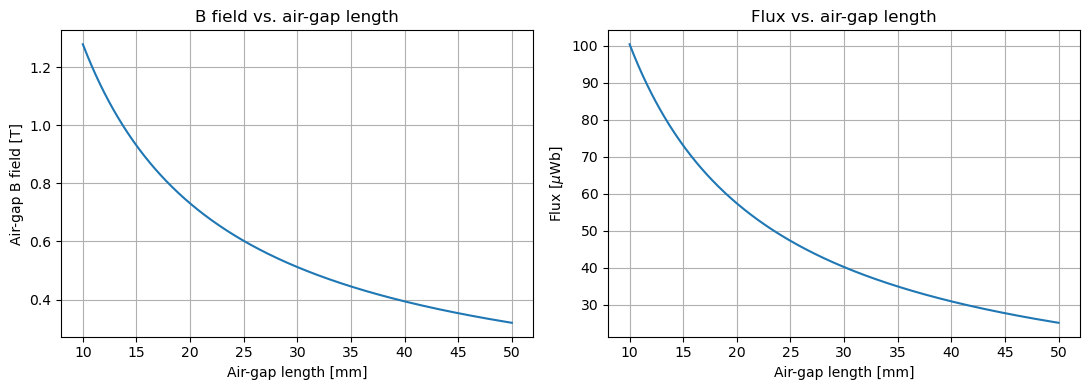

In [26]:
gap_lengths = np.linspace(10e-3, 50e-3, 400)  # sweep 0.1 mm to 5 mm

# Rebuild elements with the swept air-gap length as an array
magnet_sweep = ReluctanceElement(length=l_magnet, mu_r=mu_r_magnet, area=A_magnet)
core_sweep = ReluctanceElement(length=(136.8+20+10)*1e-3, mu_r=4000, area=A_magnet)
air_gap_sweep = ReluctanceElement(length=gap_lengths, mu_r=1.0, area=np.pi*(5e-3)**2)

elements_sweep = [magnet_sweep, core_sweep, air_gap_sweep]

flux_sweep = solve_series_circuit(MMF, elements_sweep)
B_gap_sweep = air_gap_sweep.B_field(flux_sweep)
H_gap_sweep = air_gap_sweep.H_field(flux_sweep)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(gap_lengths * 1e3, B_gap_sweep)
axes[0].set_xlabel("Air-gap length [mm]")
axes[0].set_ylabel("Air-gap B field [T]")
axes[0].set_title("B field vs. air-gap length")
axes[0].grid(True)

axes[1].plot(gap_lengths * 1e3, flux_sweep * 1e6)
axes[1].set_xlabel("Air-gap length [mm]")
axes[1].set_ylabel("Flux [$\mu$Wb]")
axes[1].set_title("Flux vs. air-gap length")
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Sweeping two variables at once (e.g. gap length x gap area)

Use `np.meshgrid` for 2D sweeps — same idea, still no changes to the class.


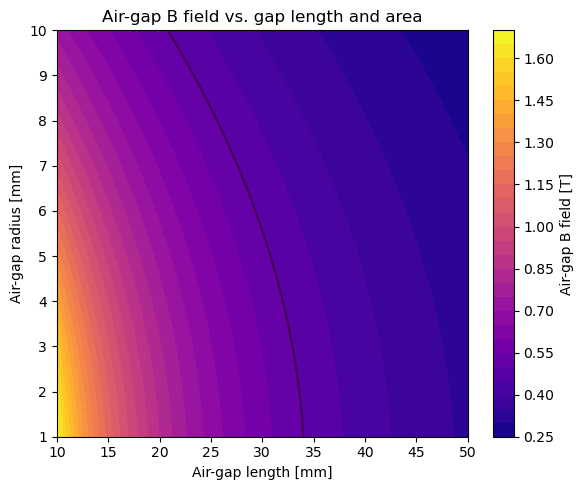

In [37]:
gap_lengths_2d = np.linspace(10e-3, 50e-3, 100)
gap_areas_2d = np.linspace(np.pi*(0.001)**2, np.pi*(0.01)**2, 1000)
L_grid, A_grid = np.meshgrid(gap_lengths_2d, gap_areas_2d)

air_gap_2d = ReluctanceElement(length=L_grid, mu_r=1.0, area=A_grid)
elements_2d = [
    ReluctanceElement(length=l_magnet, mu_r=mu_r_magnet, area=A_magnet),
    ReluctanceElement(length=50e-3, mu_r=4000, area=200e-6),
    air_gap_2d,
]

flux_2d = solve_series_circuit(MMF, elements_2d)
B_gap_2d = air_gap_2d.B_field(flux_2d) 

plt.figure(figsize=(6, 5))
cs = plt.contourf(L_grid * 1e3, np.sqrt(A_grid * 1e6/np.pi), B_gap_2d, levels=30, cmap="plasma")
plt.contour(L_grid*1e3, np.sqrt(A_grid * 1e6/np.pi), B_gap_2d, levels=[0.5])
plt.colorbar(cs, label="Air-gap B field [T]")
plt.xlabel("Air-gap length [mm]")
plt.ylabel("Air-gap radius [mm]")
plt.title("Air-gap B field vs. gap length and area")
plt.tight_layout()
plt.show()


## Notes / extending this

- For a **non-linear** core (saturating steel), replace `mu_r` with a
  field-dependent value and iterate (e.g. fixed-point or `scipy.optimize`)
  since `mu_r` would depend on `H`, which depends on `flux`, which depends on
  `mu_r`.
- For **multiple parallel paths** or more complex topologies, extend
  `solve_series_circuit` into a small mesh/nodal solver (treat each
  `ReluctanceElement.reluctance` like a resistor and reuse circuit theory:
  series adds, parallel is $1/\mathcal{R}_{eq} = \sum 1/\mathcal{R}_i$).
- All PM constants (`B_r`, `mu_r_magnet`) and geometry are plain floats, so
  swap in datasheet values for real magnet grades (N35, N42, SmCo, ferrite,
  etc.) as needed.
